# Pooling Breakeven Contours

For each pooling policy (amb-only, fac-only, both), compute the delta T1 mortality
vs stovepipe across the (bcas_rate × ccp_r1_inter_bn_min) space.

Show the zero-contour (breakeven line) under different wave assumptions,
sliced from the same LHS dataset.

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# ── CONFIGURATION ────────────────────────────────────────────────────────────
FOLDER_NAME = "20260604_235938_scenario_2btg_1ccp_each"  # <-- paste output folder name here
OUTCOME = "death_rate_T1_BCAS"

# Wave scenarios to slice — (waves_per_day range, wave_duration_min range, label)
WAVE_SLICES = [
    {"label": "Baseline (2w, 20-40m)",    "wpd": (1.5, 2.5), "wdm": (20, 40)},
    {"label": "Short intense (3-5w, 1-15m)", "wpd": (3, 5),  "wdm": (1, 15)},
    {"label": "Long mild (1w, 50-120m)",   "wpd": (0.5, 1.5), "wdm": (50, 120)},
    {"label": "Frequent medium (3-5w, 20-40m)", "wpd": (3, 5), "wdm": (20, 40)},
]
# ─────────────────────────────────────────────────────────────────────────────

df = pd.read_csv(paths.MULTI_RUN_OUTPUT / FOLDER_NAME / "results.csv")
print(f"Loaded {len(df)} runs")
print(f"Policies: {df[['facility_eligibility', 'ambulance_eligibility']].drop_duplicates().values.tolist()}")

Loaded 2000 runs
Policies: [[0, 0], [1, 0], [0, 1], [1, 1]]


In [2]:
# ── Build scenario key and split by policy ───────────────────────────────────
UNCERTAINTIES = [c for c in ["seed", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min",
                             "bcas_rate", "waves_per_day", "wave_duration_min"] if c in df.columns]

POLICIES = {
    "stovepipe":  (0, 0),
    "amb_only":   (0, 1),
    "fac_only":   (1, 0),
    "both":       (1, 1),
}

splits = {}
for name, (fac, amb) in POLICIES.items():
    sub = df[(df["facility_eligibility"] == fac) & (df["ambulance_eligibility"] == amb)].copy()
    splits[name] = sub
    print(f"{name} (fac={fac}, amb={amb}): {len(sub)} runs")

# ── Compute deltas relative to stovepipe ────────────────────────────────────
base = splits["stovepipe"][UNCERTAINTIES + [OUTCOME]]
deltas = {}
for name in ["amb_only", "fac_only", "both"]:
    merged = base.merge(
        splits[name][UNCERTAINTIES + [OUTCOME]],
        on=UNCERTAINTIES, suffixes=("_base", "_pool")
    )
    merged["delta"] = merged[f"{OUTCOME}_pool"] - merged[f"{OUTCOME}_base"]
    deltas[name] = merged
    n_hurt = (merged["delta"] > 0).sum()
    print(f"\n{name}: {len(merged)} matched, pooling hurt in {n_hurt} ({n_hurt/len(merged):.1%}), mean delta={merged['delta'].mean():.4f}")

stovepipe (fac=0, amb=0): 500 runs
amb_only (fac=0, amb=1): 500 runs
fac_only (fac=1, amb=0): 500 runs
both (fac=1, amb=1): 500 runs

amb_only: 500 matched, pooling hurt in 81 (16.2%), mean delta=-0.1609

fac_only: 500 matched, pooling hurt in 13 (2.6%), mean delta=-0.0013

both: 500 matched, pooling hurt in 79 (15.8%), mean delta=-0.1760


In [3]:
def slice_by_waves(merged_df, wpd_range, wdm_range):
    """Filter to runs within given wave parameter ranges."""
    mask = (
        (merged_df["waves_per_day"] >= wpd_range[0]) &
        (merged_df["waves_per_day"] <= wpd_range[1]) &
        (merged_df["wave_duration_min"] >= wdm_range[0]) &
        (merged_df["wave_duration_min"] <= wdm_range[1])
    )
    return merged_df[mask]

def interpolate_delta(sub, grid_x, grid_y):
    """Interpolate delta onto a regular (bcas_rate × inter_bn_distance) grid."""
    points = sub[["bcas_rate", "ccp_r1_inter_bn_min"]].values
    values = sub["delta"].values
    if len(points) < 10:
        return np.full(grid_x.shape, np.nan)
    return griddata(points, values, (grid_x, grid_y), method="linear")

# ── Grid for interpolation ───────────────────────────────────────────────────
bcas_grid = np.linspace(df["bcas_rate"].min(), df["bcas_rate"].max(), 80)
dist_grid = np.linspace(df["ccp_r1_inter_bn_min"].min(), df["ccp_r1_inter_bn_min"].max(), 80)
grid_x, grid_y = np.meshgrid(bcas_grid, dist_grid)
print(f"Grid: {len(bcas_grid)} bcas × {len(dist_grid)} distance")

Grid: 80 bcas × 80 distance


## Breakeven Contours by Policy

Each subplot = one pooling policy. Each coloured line = one wave scenario.
Green region (below the line) = pooling helps. Red region (above) = pooling hurts.

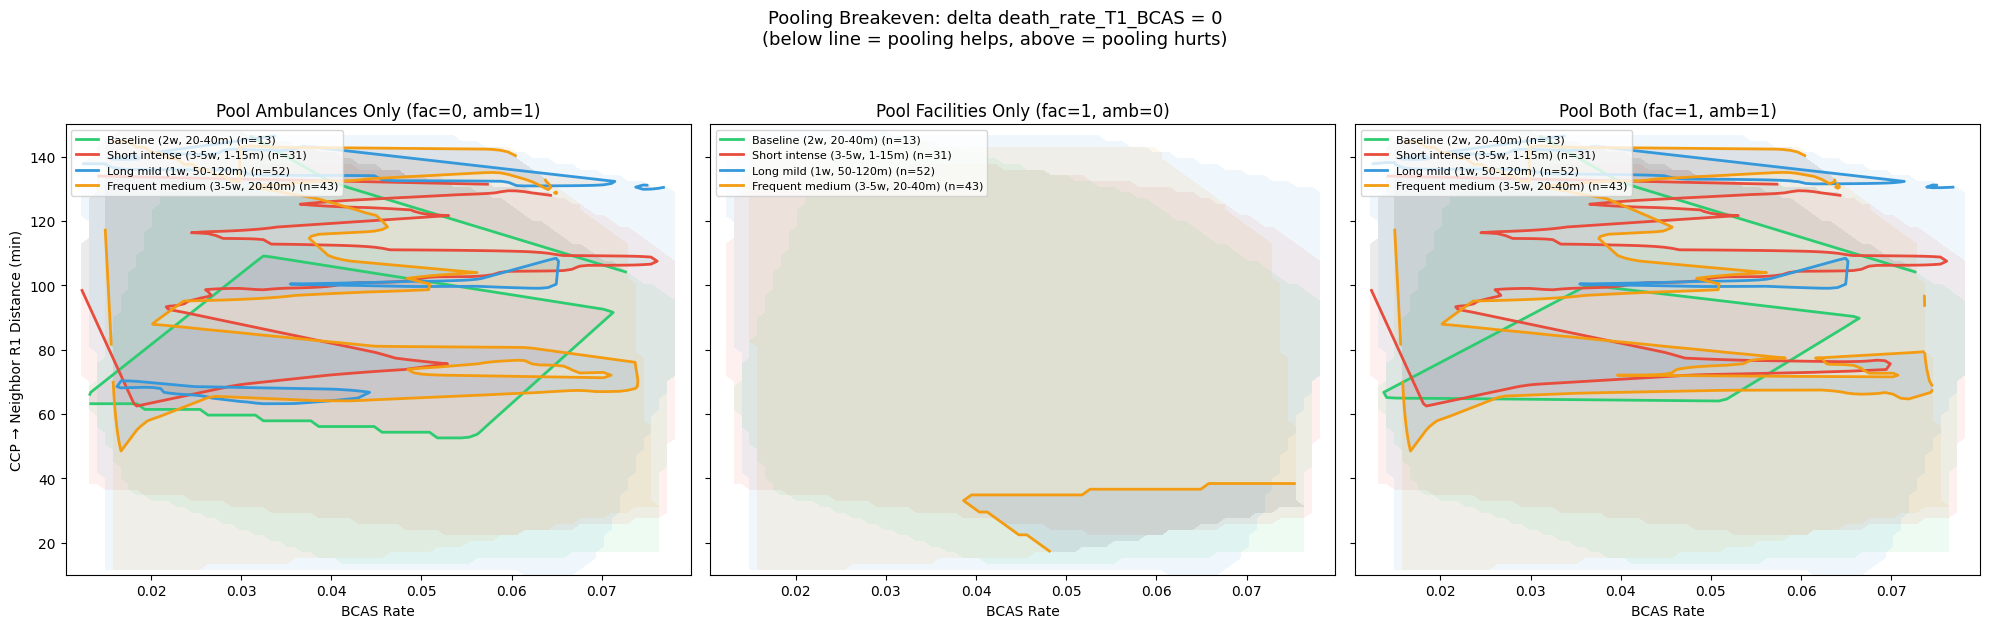

In [4]:
policy_labels = {
    "amb_only": "Pool Ambulances Only (fac=0, amb=1)",
    "fac_only": "Pool Facilities Only (fac=1, amb=0)",
    "both":     "Pool Both (fac=1, amb=1)",
}
colors = ["#2ecc71", "#e74c3c", "#3498db", "#f39c12"]

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)

for ax, policy_name in zip(axes, ["amb_only", "fac_only", "both"]):
    merged = deltas[policy_name]

    for ws, color in zip(WAVE_SLICES, colors):
        sub = slice_by_waves(merged, ws["wpd"], ws["wdm"])
        if len(sub) < 10:
            print(f"  {policy_name} / {ws['label']}: only {len(sub)} points, skipping")
            continue

        z = interpolate_delta(sub, grid_x, grid_y)
        # breakeven contour at delta = 0
        cs = ax.contour(grid_x, grid_y, z, levels=[0], colors=[color], linewidths=2)
        # shade: green where pooling helps (delta < 0)
        ax.contourf(grid_x, grid_y, z, levels=[-1, 0, 1], colors=[color, "none"], alpha=0.08)
        # label
        if cs.allsegs[0]:
            ax.plot([], [], color=color, linewidth=2, label=f"{ws['label']} (n={len(sub)})")

    ax.set_xlabel("BCAS Rate")
    ax.set_title(policy_labels[policy_name])
    ax.legend(fontsize=8, loc="upper left")

axes[0].set_ylabel("CCP → Neighbor R1 Distance (min)")
fig.suptitle(f"Pooling Breakeven: delta {OUTCOME} = 0\n(below line = pooling helps, above = pooling hurts)",
             fontsize=13, y=1.04)
plt.tight_layout()
plt.show()

## Heatmaps — Delta Mortality per Policy × Wave Scenario

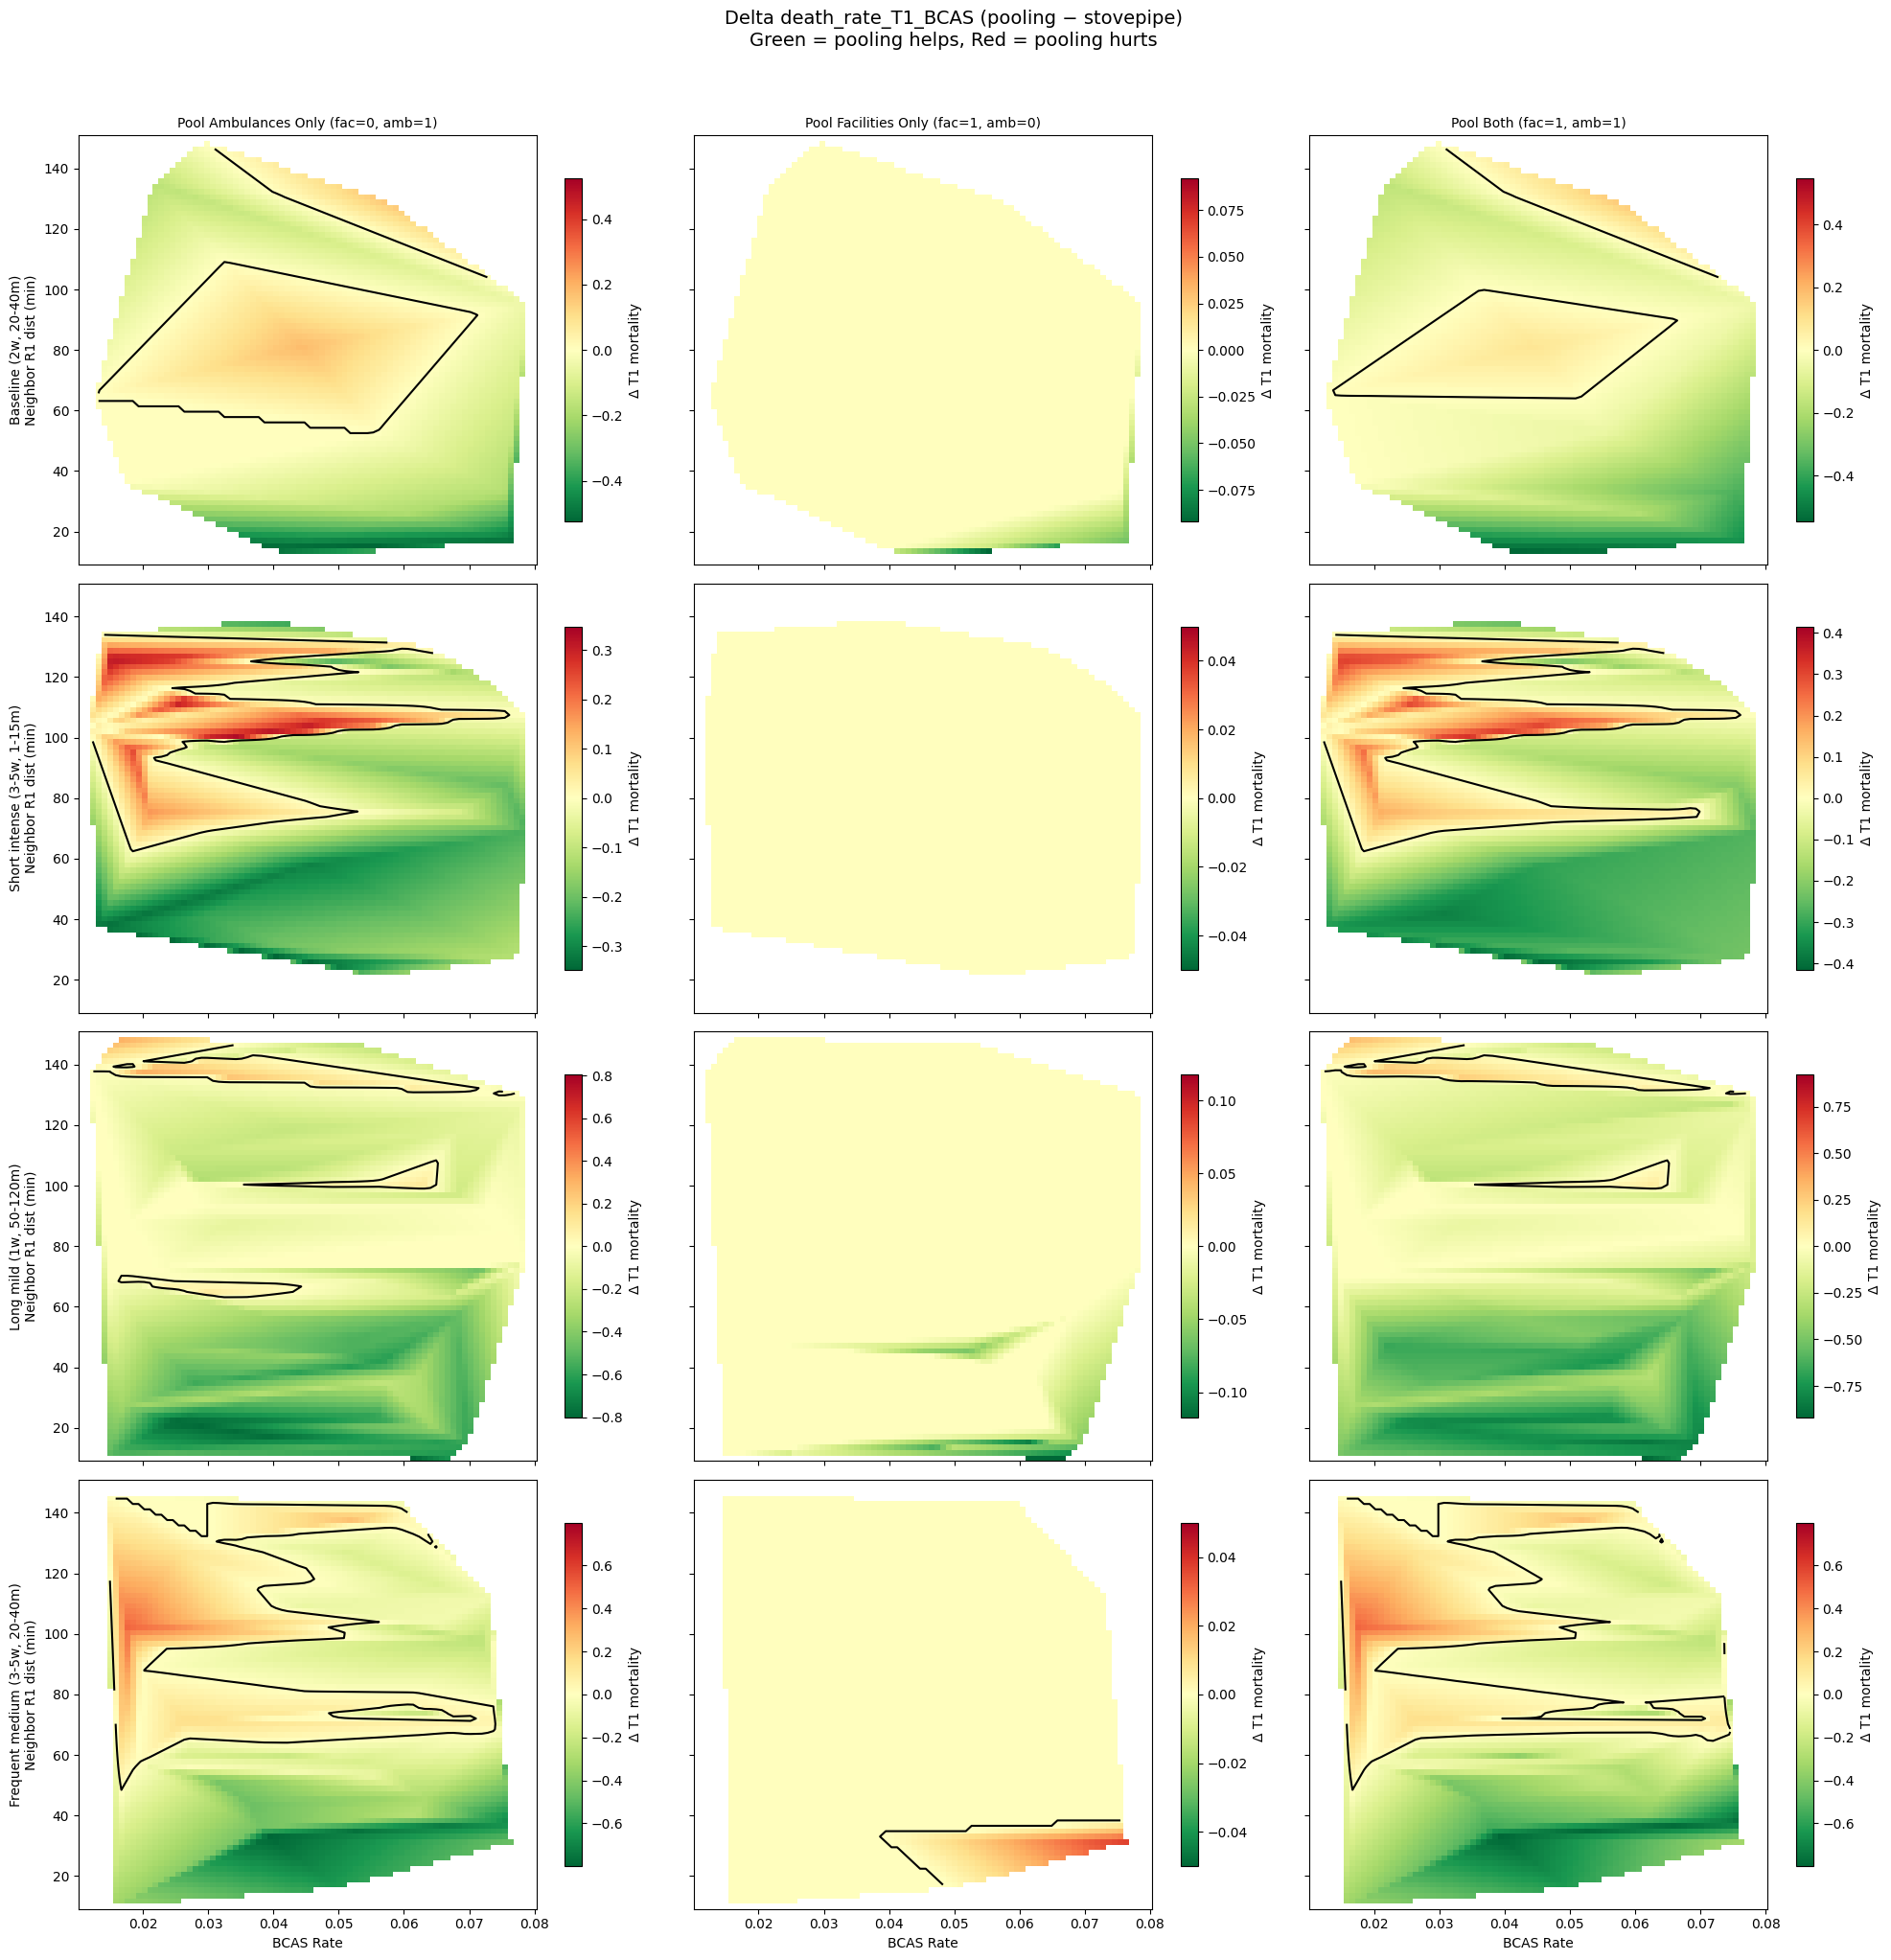

In [5]:
fig, axes = plt.subplots(len(WAVE_SLICES), 3, figsize=(20, 5 * len(WAVE_SLICES)), sharey=True, sharex=True)

for row, ws in enumerate(WAVE_SLICES):
    for col, policy_name in enumerate(["amb_only", "fac_only", "both"]):
        ax = axes[row, col]
        sub = slice_by_waves(deltas[policy_name], ws["wpd"], ws["wdm"])
        z = interpolate_delta(sub, grid_x, grid_y)

        vabs = max(0.05, np.nanmax(np.abs(z)) if not np.all(np.isnan(z)) else 0.05)
        im = ax.pcolormesh(grid_x, grid_y, z, cmap="RdYlGn_r", vmin=-vabs, vmax=vabs, shading="auto")
        ax.contour(grid_x, grid_y, z, levels=[0], colors="black", linewidths=1.5)

        if row == 0:
            ax.set_title(policy_labels[policy_name], fontsize=10)
        if col == 0:
            ax.set_ylabel(f"{ws['label']}\nNeighbor R1 dist (min)")
        if row == len(WAVE_SLICES) - 1:
            ax.set_xlabel("BCAS Rate")

        plt.colorbar(im, ax=ax, shrink=0.8, label="Δ T1 mortality")

fig.suptitle(f"Delta {OUTCOME} (pooling − stovepipe)\nGreen = pooling helps, Red = pooling hurts",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()